# Compare planes candidatos en un conjunto geológico

**Pregunta:** ¿El plan con mayor VPN pronosticado también obtiene el mejor P10 en las mismas realizaciones correlacionadas?

**Level:** 2 · Método en práctica

**Prerequisites:** Complete primero el nivel 1 de incertidumbre.

**Reading time:** 24 minutes

## Objetivos

Este notebook compara planes candidatos antes de observar los resultados geológicos. Separa retorno esperado de P10 de cola inferior y distingue elegir entre un conjunto finito de planes de reoptimizar cuando llega información. Cada plan procede de una llamada independiente a OreBlocks sobre la misma instancia. Todos se evalúan en las mismas realizaciones con semilla, por lo que las diferencias son pareadas por escenario y no dependen de sorteos distintos. Sigue siendo análisis de escenarios, no un programa estocástico: los planes se fijan antes de puntuar, el conjunto es sintético y no está condicionado por sondajes. Al terminar, interprete por qué el mejor plan por media puede diferir del mejor por P10 e indique qué evidencia requiere una decisión minera real.

## Preparación

Desde la raíz del repositorio, instale una vez el entorno fijado con `pip install oreblocks==0.6.5 numpy==2.5.1 scipy==1.18.1 matplotlib==3.11.2`. Este notebook no instala paquetes; la celda de imports informa las versiones activas. `oreblocks==0.6.5`.

```bash
pip install oreblocks==0.6.5 numpy==2.5.1 scipy==1.18.1 matplotlib==3.11.2
```

In [1]:
# Importe la canalizacion documentada y reporte las versiones activas.
import importlib.metadata as metadata
import sys
from pathlib import Path
import matplotlib.pyplot as plt
sys.path.insert(0, str(Path('../../../data-pipeline').resolve()))
from pipeline.io.schema import Case, DepositSpec, Scenario
from pipeline.model.instances import build_instance
import oreblocks as ob
for package in ('oreblocks', 'numpy', 'scipy', 'matplotlib'):
    print(package, metadata.version(package))

oreblocks 0.6.5
numpy 2.5.1
scipy 1.18.1
matplotlib 3.11.2


## Datos

La canalización didáctica de PhaseFlow, con licencia MIT, construye una veta sintética declarada: dimensiones 4×4×3, semilla 31, cuatro períodos y descuento de 8 %. Genera valores, coeficientes de recursos, coordenadas y precedencias. No se modifican valores MineLib. OreBlocks 0.6.5 aporta métodos de planificación e incertidumbre. El conjunto es un generador de estrés lognormal, correlacionado espacialmente y con semilla; no es geología observada ni una simulación condicional. Las 24 realizaciones equiprobables se reproducen abajo. Mantenga esta procedencia en cada interpretación: las realizaciones sintéticas muestran comportamiento bajo supuestos declarados, no su probabilidad en una operación real.

## Método



El conjunto contiene realizaciones equiprobables; por ello, media aritmética y P10 empírico resumen este experimento finito. P10 no es una garantía de peor caso y 24 realizaciones dan resolución limitada en la cola. `value_of_plan_selection` mide la ganancia esperada de observar una realización y elegir el mejor de estos planes fijos. No es un óptimo con información perfecta y no debe llamarse EVPI. Este notebook solo vuelve a puntuar candidatos fijos. El notebook complementario 03 mide una cota inferior del valor de replanificar mediante búsqueda desde una única política ex ante en cada realización. El máximo del menú por realización es un oráculo diagnóstico, nunca la base de replanificación; EVPI aún requiere recursión óptima global por realización.

### Paso 1: construya la entrada declarada



In [2]:
# Declare un caso reproducible y construya la instancia validada.
case = Case(
    id='uncertainty-vein-4x4x3', category='teaching',
    title_en='Small synthetic vein', title_es='Veta sintetica pequena',
    deposit=DepositSpec(kind='twin', archetype='vein', dims=(4, 4, 3), seed=31),
    scenario=Scenario(
        periods=4, discount_rate=0.08, capacity_fraction=(0.70, 0.50),
        resource_names=('mining', 'processing'),
    ),
)
instance = build_instance(case)
print('contrato valido:', instance.report.ok, '| bloques:', instance.n_blocks)

contrato valido: True | bloques: 48


### Paso 2: resuelva la referencia determinista



In [3]:
# Calcule un candidato factible con la estrategia de tiempos esperados.
schedule, _ = ob.solve_cpit(
    instance.cpit, instance.precedence,
    method='expected', local_search=False,
)
print(schedule.method, '| VPN:', round(schedule.npv, 2))

toposort:expected[r1] | VPN: 179191.57


### Paso 3: agregue un candidato topológico voraz

El método voraz aplica otra prioridad y respeta el grafo de precedencias. Su VPN determinista no mide riesgo; conservamos el resultado completo para puntuar después la asignación devuelta.

In [4]:
# Calcule un candidato factible con la estrategia voraz.
toposort_greedy, _ = ob.solve_cpit(
    instance.cpit, instance.precedence,
    method='greedy', local_search=False,
)
print(toposort_greedy.method, '| VPN:', round(toposort_greedy.npv, 2))

toposort:greedy | VPN: 179593.14


### Paso 4: agregue un candidato refinado localmente

La búsqueda local intenta movimientos factibles que mejoren un plan de valor esperado. Es una heurística, no una certificación de optimalidad global. Si dos métodos producen el mismo plan aquí, es un resultado de esta instancia pequeña, no una prueba de equivalencia.

In [5]:
# Calcule un candidato factible con la estrategia de tiempos esperados.
expected, _ = ob.solve_cpit(
    instance.cpit, instance.precedence,
    method='expected', local_search=True,
)
print(expected.method, '| VPN:', round(expected.npv, 2))

toposort:expected[r1]+shift-ls | VPN: 179191.57


### Paso 5: incluya el método de ventana respaldado por literatura

La estrategia de ventana aporta una tercera regla de secuenciación. Se ejecuta una vez con valores base y su asignación queda fija en todas las realizaciones. Esto aísla la robustez de un plan elegido de antemano; no mide el valor de adaptarlo al observar la geología.

In [6]:
# Construya la guia LP y ejecute la heuristica publicada de ventana.
window_relaxation = ob.cpit_lp_relaxation(
    instance.cpit, instance.precedence, resource=0,
)
sliding_window = ob.sliding_window_schedule(
    instance.cpit, instance.precedence, window=2, fix=1,
    node_limit=50, mip_gap=0.01, relaxation=window_relaxation,
)
print(sliding_window.method, '| VPN:', round(sliding_window.npv, 2))

sliding-window(w=2,f=1) | VPN: 237344.67


### Paso 6: genere valores correlacionados



In [7]:
# Genere valores correlacionados sin cambiar tonelaje ni capacidad.
ensemble = ob.perturb_values(
    instance.cpit.value, instance.x, instance.y, instance.level,
    n=24, sigma=0.25, correlation_blocks=2.0, seed=19,
)
print('realizaciones:', ensemble.n_realisations, '| sigma:', ensemble.sigma)
print('Aviso: conjunto sintetico correlacionado; no es una simulacion condicional')

realizaciones: 24 | sigma: 0.25
Aviso: conjunto sintetico correlacionado; no es una simulacion condicional


### Paso 7: puntúe la decisión fija



In [8]:
# Compare los planes identificados en las mismas realizaciones.
schedules = {
    'expected-base': schedule.period_of_block,
    toposort_greedy.method: toposort_greedy.period_of_block,
    'expected-local-search': expected.period_of_block,
    sliding_window.method: sliding_window.period_of_block,
}
risk = ob.evaluate_across(instance.cpit, ensemble, schedules)
for name, mean, p10 in zip(risk.method_ids, risk.expected, risk.p10):
    print(name, '| media:', round(float(mean), 2), '| P10:', round(float(p10), 2))
print('mejor por media:', risk.best_by_expected, '| mejor por P10:', risk.best_by_p10)

expected-base | media: 173035.23 | P10: 129694.82
toposort:greedy | media: 172983.1 | P10: 130723.07
expected-local-search | media: 173035.23 | P10: 129694.82
sliding-window(w=2,f=1) | media: 232257.98 | P10: 187607.51
mejor por media: sliding-window(w=2,f=1) | mejor por P10: sliding-window(w=2,f=1)


La comparación usa números aleatorios comunes: cada candidato se evalúa con los mismos campos espaciales de valor. Este emparejamiento importa porque restar promedios obtenidos de campos independientes mezclaría las diferencias entre políticas con ruido de muestreo. Para la realización j y la política k, cada entrada de la matriz es el valor descontado de la asignación temporal fija bajo esa realización. La media estima el desempeño promedio bajo esta distribución sintética declarada; P10 describe un resultado de cola inferior, no un piso garantizado. Una política puede liderar en la media y perder en P10 si concentra valor en pocos bloques inciertos de alto valor.

La geología muestreada es una perturbación correlacionada de los valores sintéticos de base; por eso los bloques vecinos no se comportan como lanzamientos independientes. El supuesto afecta la dispersión: una correlación más fuerte puede crear regiones coherentes de valor alto o bajo y aumentar la importancia de la exposición espacial del plan. La semilla fija un experimento reproducible, pero una sola semilla no cuantifica la incertidumbre de la distribución. Un profesional debería repetir la comparación con longitudes de correlación y escalas de perturbación defendibles, y reportar si cambia el orden de las políticas. El intervalo entre esos modelos es un rango de sensibilidad, no un intervalo estadístico de confianza.

El conjunto de candidatos también limita la pregunta. La política con mejor P10 es solo la mejor entre los planes generados aquí; no es el plan óptimo con aversión al riesgo. Estas puntuaciones no reoptimizan después de observar una realización, no modelan costos fuera del campo de valor declarado ni incorporan un posterior geológico calibrado. Ayudan a filtrar planes por exposición a pérdidas y a identificar bloques que impulsan el riesgo. Una decisión productiva requiere conciliar los resultados con geología medida, costos, recuperación y capacidades antes de convertir el orden en recomendación operativa.


## Resultados

**Respuesta:** El candidato de ventana deslizante lidera ambos criterios: VPN medio 232257.98 y P10 187607.51 en las 24 realizaciones compartidas. El valor de selección del menú finito es 0.00; en este caso el menú no añade valor medio al elegir tras observar una realización. Esto no significa que la información no valga ni que EVPI sea cero.

In [9]:
# Muestre las cantidades exactas usadas en la respuesta.
print(f'media={risk.expected[0]:.2f}; P10={risk.p10[0]:.2f}; P90={risk.p90[0]:.2f}')
print(f'base={risk.mean_model_npv[0]:.2f}; optimismo={risk.deterministic_optimism[0]:.2f}')

media=173035.23; P10=129694.82; P90=226632.30
base=179191.57; optimismo=6156.34


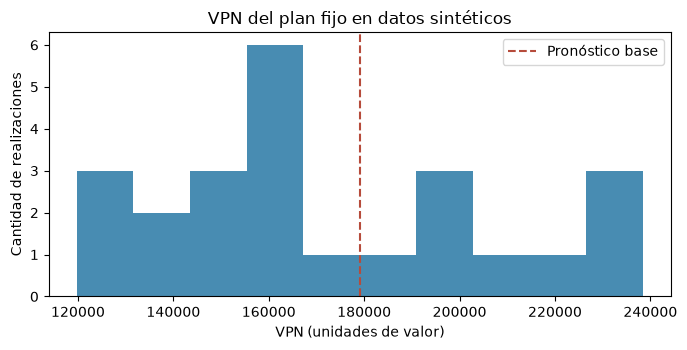

In [10]:
# Grafique las puntuaciones por escenario y marque el pronostico base.
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.hist(risk.matrix[0], bins=10, color='#2878a5', alpha=0.85)
ax.axvline(risk.mean_model_npv[0], color='#b64b3b', linestyle='--', label='Pronóstico base')
ax.set(
    title='VPN del plan fijo en datos sintéticos',
    xlabel='VPN (unidades de valor)', ylabel='Cantidad de realizaciones',
)
ax.legend()
fig.tight_layout()
plt.show()

### Figura 1

Cada barra cuenta realizaciones del plan de pronóstico fijo dentro de un intervalo de VPN, y la línea discontinua marca su puntuación media. El histograma muestra dispersión y asimetría de esta política bajo el generador correlacionado con semilla. No compara planes alternativos ni asigna probabilidades a resultados de una operación real. Una cola inferior pronunciada justificaría revisar qué bloques y períodos inciertos impulsan la exposición.


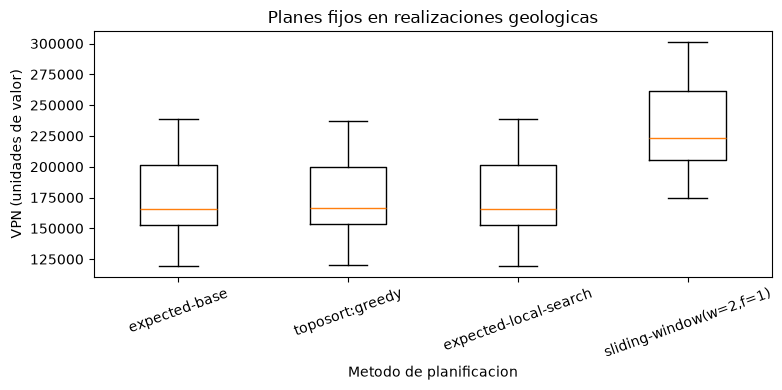

In [11]:
# Grafique la distribucion por escenarios de cada plan.
fig, ax = plt.subplots(figsize=(8, 4))
ax.boxplot(risk.matrix.T, tick_labels=risk.method_ids)
ax.set(
    title='Planes fijos en realizaciones geologicas',
    xlabel='Metodo de planificacion', ylabel='VPN (unidades de valor)',
)
ax.tick_params(axis='x', rotation=20)
fig.tight_layout()
plt.show()

### Figura 2

Cada caja resume el VPN de un candidato en las mismas 24 realizaciones de valor, por lo que las diferencias son comparaciones pareadas entre políticas. La mediana y el rango intercuartil muestran dispersión típica; bigotes y puntos exponen realizaciones extremas. El solapamiento es descriptivo, no una prueba de significancia. El gráfico omite planes fuera del conjunto y no determina una medida de riesgo universalmente preferible.


Los nombres y valores seleccionados responden la pregunta de decisión usando los candidatos calculados y las mismas realizaciones.

In [12]:
# Calcule el valor esperado y las cantidades de cola inferior.
print('mejor por media:', risk.best_by_expected, round(float(max(risk.expected)), 2))
print('mejor por P10:', risk.best_by_p10, round(float(max(risk.p10)), 2))
print('valor de seleccion del menu finito:', round(risk.value_of_plan_selection, 2))

mejor por media: sliding-window(w=2,f=1) 232257.98
mejor por P10: sliding-window(w=2,f=1) 187607.51
valor de seleccion del menu finito: 0.0


## Resumen



## Referencias

- PhaseFlow synthetic instance contract and builder: `data-pipeline/pipeline/io/schema.py`, `data-pipeline/pipeline/model/instances.py` (MIT).
- OreBlocks 0.6.5: `oreblocks.perturb_values` and `oreblocks.evaluate_across`.
- Blom, Pearce & Cote: https://arxiv.org/abs/2403.18213.
- Ramazan & Dimitrakopoulos: https://doi.org/10.1007/s11081-012-9186-2.
- Meagher, Dimitrakopoulos & Avis: https://doi.org/10.1134/S1062739114030132.